In [2]:
import matplotlib.pyplot as plt
import pandas as pd


# Data Storytelling

In [3]:
df = pd.read_csv("ecommerce_sales_real_world_practice.csv")
df["Date"] = pd.to_datetime(df["Date"])
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             24 non-null     datetime64[us]
 1   Product          24 non-null     str           
 2   Category         24 non-null     str           
 3   Units_Sold       24 non-null     int64         
 4   Unit_Price_USD   24 non-null     int64         
 5   Revenue_USD      24 non-null     int64         
 6   Region           24 non-null     str           
 7   Customer_Rating  24 non-null     float64       
 8   Returned_Units   24 non-null     int64         
dtypes: datetime64[us](1), float64(1), int64(4), str(3)
memory usage: 1.8 KB


,Date,Product,Category,Units_Sold,Unit_Price_USD,Revenue_USD,Region,Customer_Rating,Returned_Units
0,2026-01-05,Laptop,Computers,12,1000,12000,North,4.2,1
1,2026-01-12,Phone,Mobile,25,700,17500,South,4.5,2
2,2026-01-19,Headphones,Audio,38,100,3800,West,4.1,3
3,2026-01-26,Monitor,Computers,16,375,6000,East,4.0,1
4,2026-02-02,Keyboard,Accessories,31,100,3100,North,4.3,2


# Monthtly Revenue & Average Rating

Goal: Does customer satisfaction change alongside revenue

            Revenue_USD  Customer_Rating
Date                                    
2026-01-05        12000              4.2
2026-01-12        17500              4.5
2026-01-19         3800              4.1
2026-01-26         6000              4.0
2026-02-02         3100              4.3
2026-02-09        18000              4.4
2026-02-16        20300              4.2
2026-02-23         4200              4.6
2026-03-02         7875              4.1
2026-03-09         3500              4.5
2026-03-16        24000              4.6
2026-03-23        23100              4.3
2026-04-06         4500              4.4
2026-04-13         7125              4.2
2026-04-20         4000              4.6
2026-04-27        27000              4.7
2026-05-04        25200              4.5
2026-05-11         4800              4.7
2026-05-18         8625              4.3
2026-05-25         4400              4.4
2026-06-01        30000              4.8
2026-06-08        28700              4.6
2026-06-15      

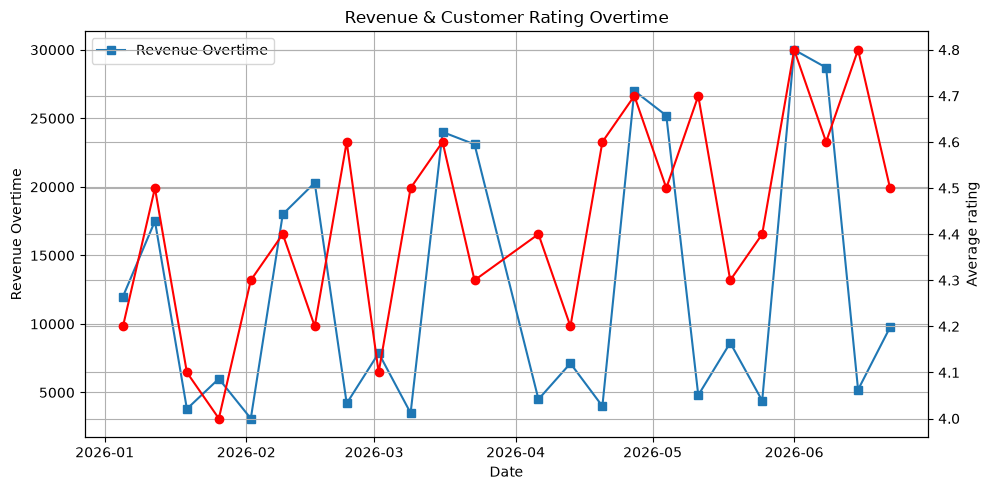

In [4]:
monthly_summary = df.groupby("Date").agg({
    "Revenue_USD": "sum",
    "Customer_Rating": "mean"
})

print(monthly_summary)

fig, ax = plt.subplots(figsize=(10, 5))

line1 = ax.plot(monthly_summary.index,
                monthly_summary["Revenue_USD"],
                marker='s',
                label='Revenue Overtime')
ax.set_xlabel("Date")
ax.set_ylabel("Revenue Overtime")
ax.grid()

ax2 = ax.twinx()

line2 = ax2.plot(monthly_summary.index,
                 monthly_summary["Customer_Rating"],
                 marker='o',
                 color='red',
                 label="Customer rating")
ax2.set_ylabel("Average rating")
ax2.grid()

lines = line1 + line2
ax.legend()

plt.title("Revenue & Customer Rating Overtime")
plt.tight_layout()

plt.show()


# Product Revenue Contribution

Goal: What percentage of the company's total revenue comes from each product

Product
Phone         37.928471
Laptop        36.672999
Monitor       13.009003
Headphones     7.433716
Keyboard       4.955811
Name: Revenue_USD, dtype: float64


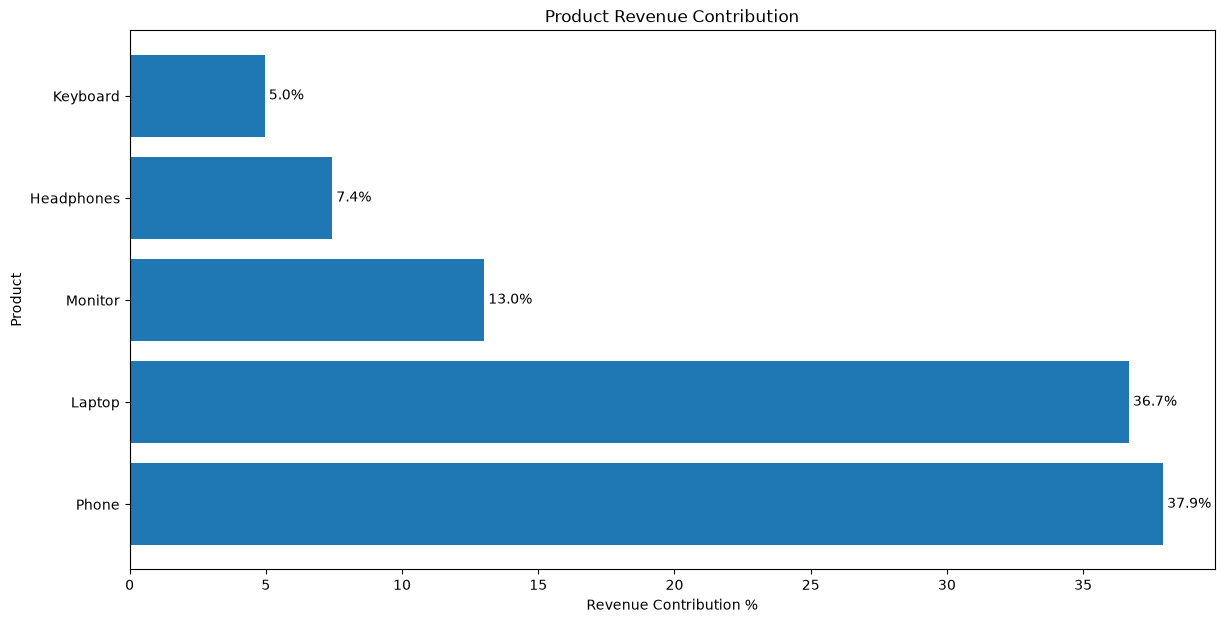

In [5]:
revenue_per_product = (
    df.groupby("Product")["Revenue_USD"].sum()
)
total_revenue = df["Revenue_USD"].sum()

calculate = (revenue_per_product / total_revenue * 100).sort_values(ascending=False)
print(calculate)

plt.figure(figsize=(14, 7))
bar = plt.barh(calculate.index,
               calculate.values)
plt.bar_label(bar,
             fmt="%1.1f%%",
             padding=3)
plt.xlabel("Revenue Contribution %")
plt.ylabel("Product")
plt.title("Product Revenue Contribution")

plt.show()

# Product Performance Matrix

Goal: Analytical thinking

In [20]:
summary = df.groupby("Product").agg({
    "Units_Sold": "sum",
    "Revenue_USD": "sum",
    "Customer_Rating": "mean",
    "Returned_Units": "sum",
})
print(summary)

highest_revenue = df.groupby("Revenue_USD")["Product"].sum()
most_units = df.groupby("Units_Sold")["Product"].sum()
return_rate = df.groupby("Product")["Returned_Units"].sum()
average_rating = df.groupby("Product")["Customer_Rating"].mean()
print(highest_revenue)
print(most_units)
print(return_rate)
print(average_rating)

            Units_Sold  Revenue_USD  Customer_Rating  Returned_Units
Product                                                             
Headphones         225        22500             4.52               9
Keyboard           150        15000             4.45               7
Laptop             111       111000             4.54               5
Monitor            105        39375             4.22               6
Phone              164       114800             4.42               9
Revenue_USD
3100       Keyboard
3500       Keyboard
3800     Headphones
4000       Keyboard
4200     Headphones
4400       Keyboard
4500     Headphones
4800     Headphones
5200     Headphones
6000        Monitor
7125        Monitor
7875        Monitor
8625        Monitor
9750        Monitor
12000        Laptop
17500         Phone
18000        Laptop
20300         Phone
23100         Phone
24000        Laptop
25200         Phone
27000        Laptop
28700         Phone
30000        Laptop
Name: Product, dtype: str

# Dashboard

Text(0, 0.5, 'Total revenue')

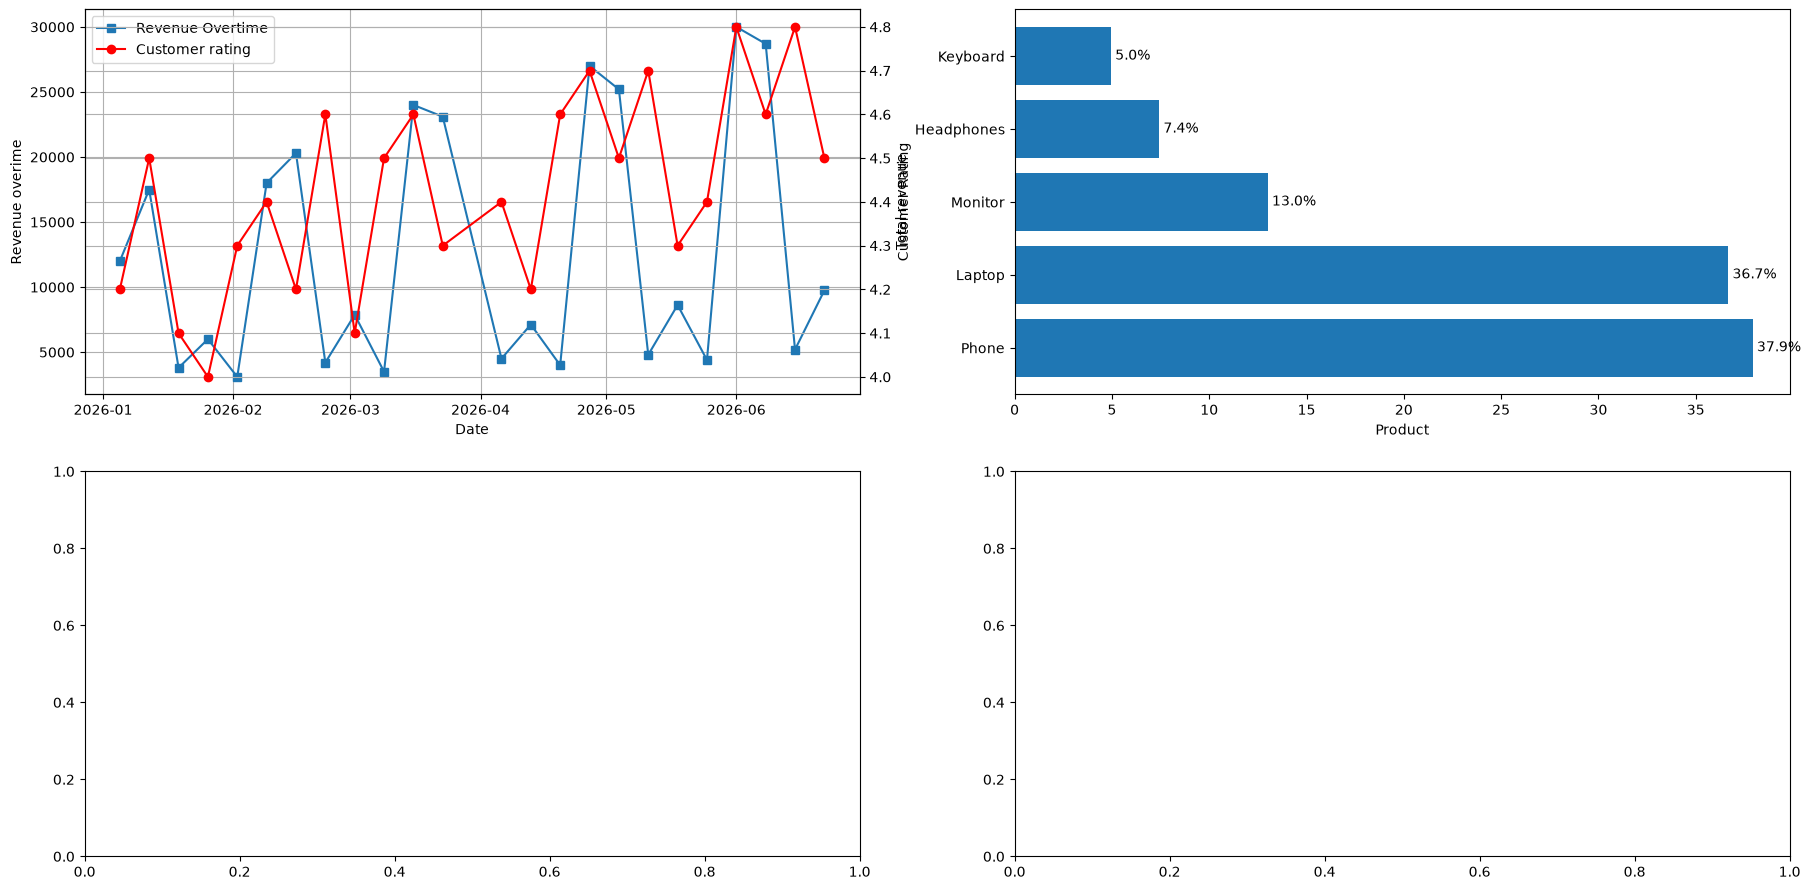

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(22, 11))

line1 = ax[0, 0].plot(monthly_summary.index,
                monthly_summary["Revenue_USD"],
                marker='s',
                label='Revenue Overtime')
ax[0, 0].set_xlabel("Date")
ax[0, 0].set_ylabel("Revenue overime")
ax[0, 0].grid()

ax2_00 = ax[0, 0].twinx()

line2 = ax2_00.plot(monthly_summary.index,
                 monthly_summary["Customer_Rating"],
                 marker='o',
                 color='red',
                 label="Customer rating")
ax2_00.set_ylabel("Customer Rating")
ax2_00.grid()

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax[0, 0].legend(lines, labels, loc="upper left")


bar = ax[0, 1].barh(calculate.index,
               calculate.values
               )
ax[0, 1].bar_label(bar, 
                   fmt="%1.1f%%",
                   padding=3
                   )
ax[0, 1].set_xlabel("Product")
ax[0, 1].set_ylabel("Total revenue")








# Product Performance Dashboard

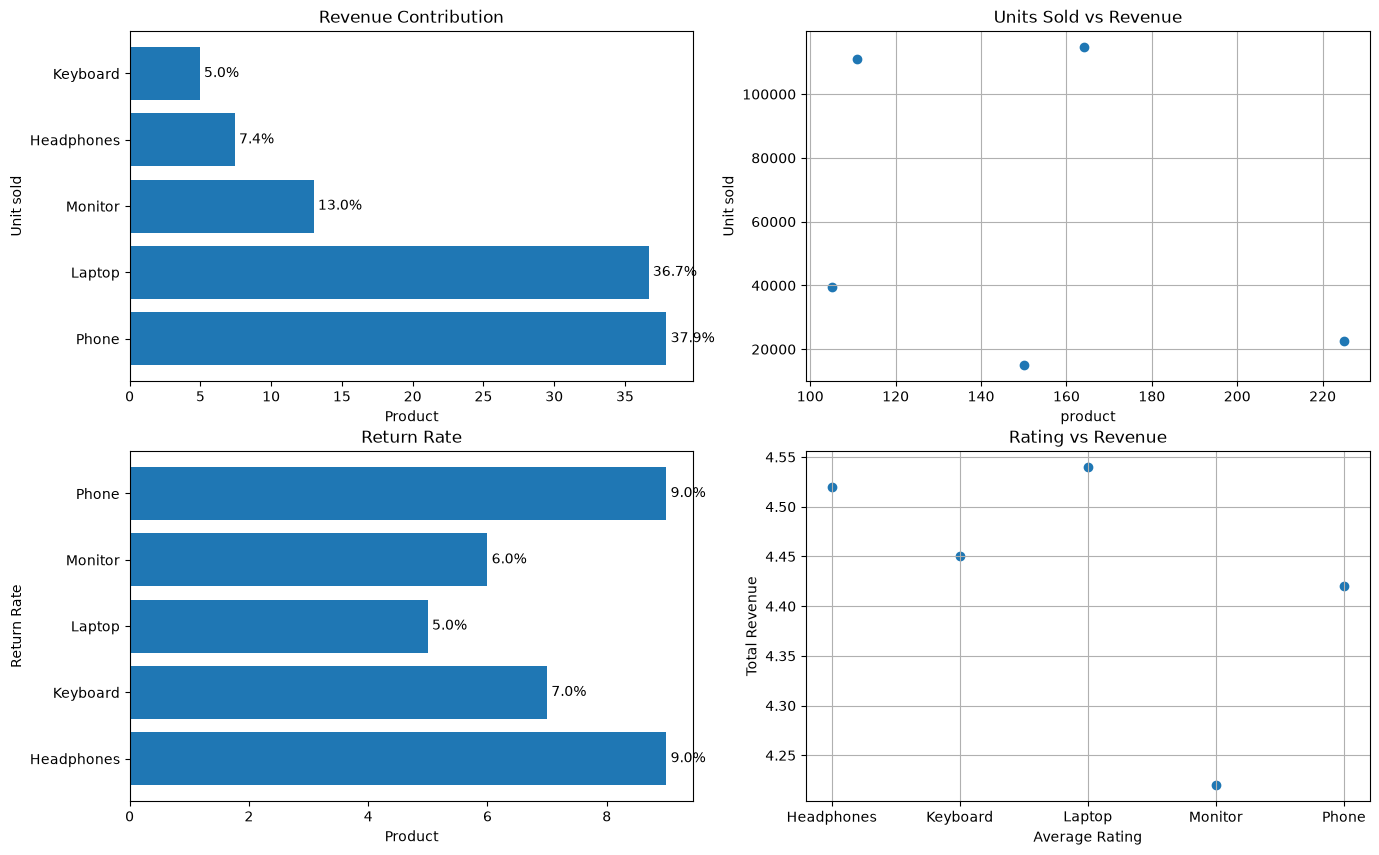

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(16, 10))

bar = ax[0, 0].barh(calculate.index,
                    calculate.values)
ax[0, 0].bar_label(bar,
                   fmt="%1.1f%%",
                   padding=3)
ax[0, 0].set_xlabel("Product")
ax[0, 0].set_ylabel("Unit sold")
ax[0, 0].set_title("Revenue Contribution")

ax[0, 1].scatter(summary["Units_Sold"],
                 summary["Revenue_USD"])
ax[0, 1].set_xlabel("product")
ax[0, 1].set_ylabel("Unit sold")
ax[0, 1].set_title("Units Sold vs Revenue")
ax[0, 1].grid()

bar1  = ax[1, 0].barh(return_rate.index,
              return_rate.values)
ax[1, 0].bar_label(bar1,
                    fmt="%1.1f%%",
                    padding=3)
ax[1, 0].set_xlabel("Product")
ax[1, 0].set_ylabel("Return Rate")
ax[1, 0].set_title("Return Rate")

ax[1, 1].scatter(average_rating.index,
                 average_rating.values)
ax[1, 1].set_xlabel("Average Rating")
ax[1, 1].set_ylabel("Total Revenue")
ax[1, 1].set_title("Rating vs Revenue")
ax[1, 1].grid()

